<a href="https://colab.research.google.com/github/Subhaashree06/Deep-Learning-assignments/blob/main/CO1_Assessment1_AgriVision_All_Tasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSA47 Deep Learning — CO1 Assessment 1 (AgriVision)
## Google Colab notebook using the supplied `agrivision_64...npz` dataset

**Important dataset finding:** the supplied NPZ contains `X` with shape `(8707, 64, 64)`, `y` with 8,707 labels, and `names` with 30 entries. Label 0 is `.ipynb_checkpoints` and contains only 7 samples, so the notebook excludes it as a non-disease artifact. The remaining data has **8,700 images across 29 crop–disease classes (300 images/class)**. The assignment's 38-class design challenge is analysed as a changed requirement; this dataset cannot experimentally validate 38 classes because it contains only 29 valid classes.

Run the cells **from top to bottom** in Colab. When prompted, upload the NPZ file. Some experiments (especially the full scale) may take several minutes.

## Setup and load the dataset

In [ ]:
import os, time, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report,
                             log_loss, ConfusionMatrixDisplay)
from sklearn.utils import resample
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Colab upload. If running outside Colab, set NPZ_PATH to your file path.
try:
    from google.colab import files
    uploaded = files.upload()
    NPZ_PATH = next((f for f in uploaded if f.lower().endswith(".npz")), None)
except Exception:
    NPZ_PATH = "/content/agrivision_64 (2).npz"

if NPZ_PATH is None or not os.path.exists(NPZ_PATH):
    raise FileNotFoundError("Upload the supplied .npz dataset and rerun this cell.")

data = np.load(NPZ_PATH, allow_pickle=True)
X_img_all, y_all, names_all = data["X"], data["y"], data["names"]
print("Raw X:", X_img_all.shape, X_img_all.dtype)
print("Raw y:", y_all.shape, y_all.dtype)
print("names:", len(names_all))
print("Raw label counts:", dict(zip(*np.unique(y_all, return_counts=True))))

# Label 0 is a filesystem/checkpoint artifact, not a crop disease.
valid = (y_all != 0) & (y_all < len(names_all))
X_img = X_img_all[valid]
y = y_all[valid]
class_names = np.array(names_all)
# Map original label IDs to compact 0..C-1 IDs.
original_labels = np.unique(y)
label_to_index = {lab:i for i,lab in enumerate(original_labels)}
index_to_label = {i:lab for lab,i in label_to_index.items()}
y = np.array([label_to_index[v] for v in y], dtype=np.int64)
class_names_valid = np.array([class_names[index_to_label[i]] for i in range(len(original_labels))])
N, H, W = X_img.shape
C = len(class_names_valid)
X = X_img.reshape(N, -1).astype(np.float32) / 255.0
print(f"Clean dataset: {N} images, {C} classes, {H}x{W} pixels, {X.shape[1]} flattened features")
print("Class counts:", pd.Series(y).value_counts().sort_index().to_dict())
print("Class names:", list(class_names_valid))

Saving agrivision_64 (2).npz to agrivision_64 (2) (1).npz
Raw X: (8707, 64, 64) uint8
Raw y: (8707,) int64
names: 30
Raw label counts: {np.int64(0): np.int64(7), np.int64(1): np.int64(300), np.int64(2): np.int64(300), np.int64(3): np.int64(300), np.int64(4): np.int64(300), np.int64(5): np.int64(300), np.int64(6): np.int64(300), np.int64(7): np.int64(300), np.int64(8): np.int64(300), np.int64(9): np.int64(300), np.int64(10): np.int64(300), np.int64(11): np.int64(300), np.int64(12): np.int64(300), np.int64(13): np.int64(300), np.int64(14): np.int64(300), np.int64(15): np.int64(300), np.int64(16): np.int64(300), np.int64(17): np.int64(300), np.int64(18): np.int64(300), np.int64(19): np.int64(300), np.int64(20): np.int64(300), np.int64(21): np.int64(300), np.int64(22): np.int64(300), np.int64(23): np.int64(300), np.int64(24): np.int64(300), np.int64(25): np.int64(300), np.int64(26): np.int64(300), np.int64(27): np.int64(300), np.int64(28): np.int64(300), np.int64(29): np.int64(300)}
Clean 

## Task 1 — Problem structure and data representation

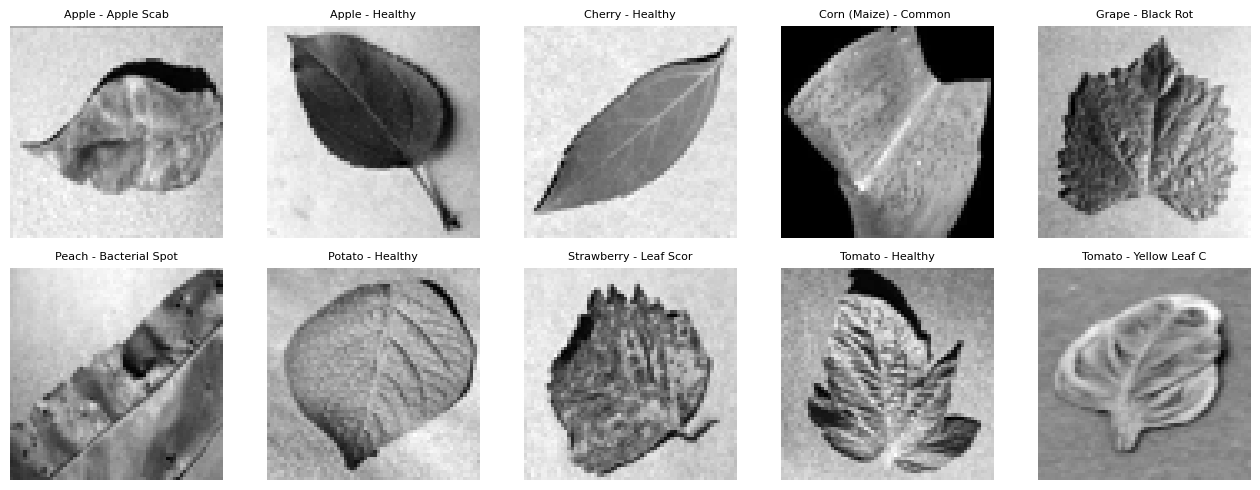

Dataset as grayscale image tensor: (8700, 64, 64) (N, 64, 64)
One image: (64, 64) matrix; flattened feature vector: (4096,)
Mini-batch of 32: (32, 4096) (32, 4096)
Integer labels for mini-batch: (32,) (32,)
One label is a scalar class index; one-hot labels would have shape: (29,)
For CNNs, a channel dimension can be added: (8700, 64, 64, 1)
First image feature-vector norms: L1=2394.6941, L2=38.9095, L-infinity=0.8078
Pixel range before scaling: 0 to 255
Pixel range after scaling: 0.0 to 1.0
Flattening changes shape only (4096 features); it removes explicit 2-D neighbourhood structure.


In [ ]:
# Show sample images and tensor shapes.
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for ax, idx in zip(axes.ravel(), np.linspace(0, N-1, 10, dtype=int)):
    ax.imshow(X_img[idx], cmap="gray")
    ax.set_title(class_names_valid[y[idx]][:22], fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

print("Dataset as grayscale image tensor:", X_img.shape, "(N, 64, 64)")
print("One image:", X_img[0].shape, "matrix; flattened feature vector:", X[0].shape)
print("Mini-batch of 32:", X[:32].shape, "(32, 4096)")
print("Integer labels for mini-batch:", y[:32].shape, "(32,)")
print("One label is a scalar class index; one-hot labels would have shape:", (C,))
print("For CNNs, a channel dimension can be added:", (N, 64, 64, 1))

v = X[0]
L1 = np.sum(np.abs(v))
L2 = np.linalg.norm(v, 2)
Linf = np.max(np.abs(v))
print(f"First image feature-vector norms: L1={L1:.4f}, L2={L2:.4f}, L-infinity={Linf:.4f}")

# Illustrate normalisation and information loss from resizing (current data is already 64x64).
print("Pixel range before scaling:", int(X_img.min()), "to", int(X_img.max()))
print("Pixel range after scaling:", float(X.min()), "to", float(X.max()))
print("Flattening changes shape only (4096 features); it removes explicit 2-D neighbourhood structure.")

## Task 2 — Feature space, PCA/SVD, eigenvalues and reconstruction

First 15 eigenvalues: [40.54936 16.81378 10.54485  8.70323  6.38915  3.56423  2.54113  2.25278
  1.73974  1.68891  1.56768  1.20453  1.18295  1.07135  0.98606]
First 15 singular values: [402.68707 259.30347 205.35054 186.55891 159.84433 119.38738 100.80655
  94.91514  83.40984  82.18234  79.178    69.40407  68.77958  65.4547
  62.79542]
Variance explained by first 10 PCs: 0.6851
Variance explained by first 50 PCs: 0.8351
Variance explained by first 100 PCs: 0.9237 (up to 100/200 fitted components)


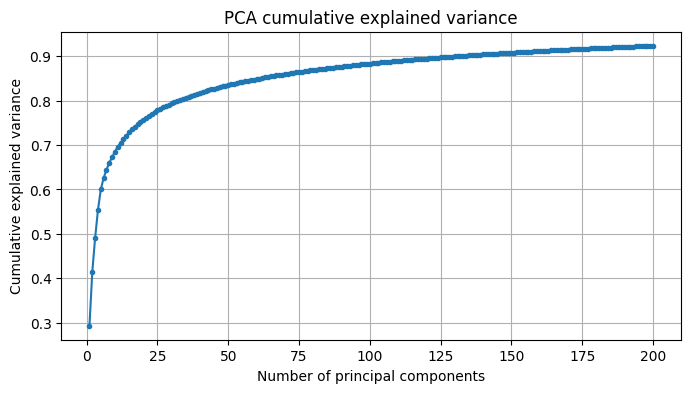

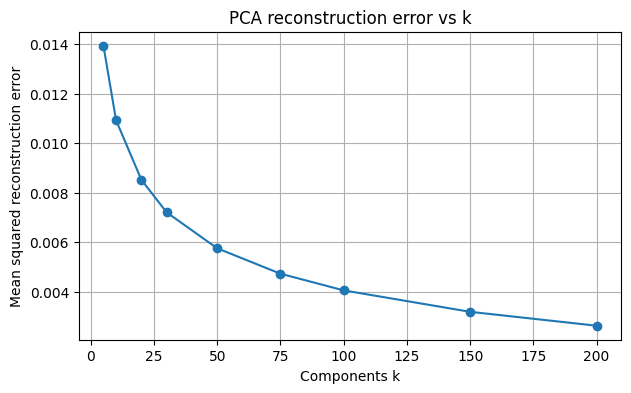

     k  mean_squared_reconstruction_error
0    5                           0.013943
1   10                           0.010925
2   20                           0.008520
3   30                           0.007202
4   50                           0.005748
5   75                           0.004721
6  100                           0.004047
7  150                           0.003180
8  200                           0.002618


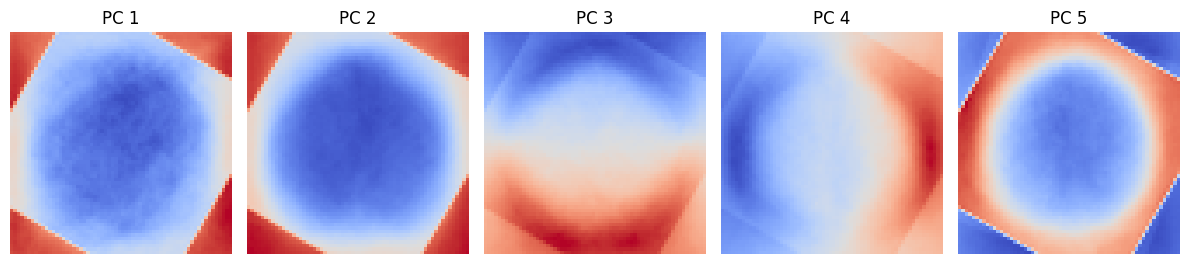

Hand-work example matrix A = [[2.0, 1.0], [1.0, 2.0]]
Characteristic equation: det(A-lambda I)=(2-lambda)^2-1=0
Eigenvalues: [1. 3.] Eigenvectors (columns):
 [[-0.70710678  0.70710678]
 [ 0.70710678  0.70710678]]
Check A v = lambda v: True


In [ ]:
# PCA on a reproducible sample to keep Colab memory/time manageable.
pca_n = min(4000, N)
rng = np.random.default_rng(RANDOM_STATE)
pca_idx = rng.choice(N, size=pca_n, replace=False)
X_pca_source = X[pca_idx]
X_centered = X_pca_source - X_pca_source.mean(axis=0, keepdims=True)

pca_full = PCA(n_components= min(200, X_centered.shape[0]-1, X_centered.shape[1]),
               svd_solver="randomized", random_state=RANDOM_STATE)
pca_full.fit(X_centered)
eigvals = (pca_full.singular_values_**2) / (pca_n - 1)
explained = pca_full.explained_variance_ratio_
cumvar = np.cumsum(explained)
print("First 15 eigenvalues:", np.round(eigvals[:15], 5))
print("First 15 singular values:", np.round(pca_full.singular_values_[:15], 5))
print("Variance explained by first 10 PCs:", round(float(cumvar[min(9,len(cumvar)-1)]), 4))
print("Variance explained by first 50 PCs:", round(float(cumvar[min(49,len(cumvar)-1)]), 4))
print("Variance explained by first 100 PCs:", round(float(cumvar[-1]), 4), "(up to 100/200 fitted components)")

plt.figure(figsize=(8,4))
plt.plot(np.arange(1, len(cumvar)+1), cumvar, marker=".")
plt.xlabel("Number of principal components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA cumulative explained variance"); plt.grid(True); plt.show()

# Reconstruction error versus k using fitted PCA components.
ks = [5, 10, 20, 30, 50, 75, 100, 150, 200]
ks = [k for k in ks if k <= len(pca_full.components_)]
Xc = X_centered[:min(500, len(X_centered))]
errs=[]
for k in ks:
    comps = pca_full.components_[:k]
    rec = (Xc @ comps.T) @ comps
    errs.append(np.mean((Xc-rec)**2))
plt.figure(figsize=(7,4)); plt.plot(ks, errs, marker="o")
plt.xlabel("Components k"); plt.ylabel("Mean squared reconstruction error")
plt.title("PCA reconstruction error vs k"); plt.grid(True); plt.show()
print(pd.DataFrame({"k":ks, "mean_squared_reconstruction_error":errs}))

# Visualise leading PCs as 64x64 images.
fig, axes = plt.subplots(1, 5, figsize=(12,3))
for i, ax in enumerate(axes):
    ax.imshow(pca_full.components_[i].reshape(64,64), cmap="coolwarm")
    ax.set_title(f"PC {i+1}"); ax.axis("off")
plt.tight_layout(); plt.show()

# A worked 2x2 eigendecomposition example.
A_small = np.array([[2., 1.], [1., 2.]])
evals, evecs = np.linalg.eigh(A_small)
print("Hand-work example matrix A =", A_small.tolist())
print("Characteristic equation: det(A-lambda I)=(2-lambda)^2-1=0")
print("Eigenvalues:", evals, "Eigenvectors (columns):\n", evecs)
print("Check A v = lambda v:", np.allclose(A_small @ evecs, evecs * evals))

## Task 3 — Probability, entropy, cross-entropy and KL divergence

In [ ]:
counts = np.bincount(y, minlength=C)
p_class = counts / counts.sum()
entropy_bits = -np.sum(p_class * np.log2(p_class + 1e-15))
print(f"Class-distribution entropy: {entropy_bits:.4f} bits; maximum for {C} balanced classes = {np.log2(C):.4f} bits")

# Train/test split and a baseline model for actual predictive distributions.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
prob_model = LogisticRegression(max_iter=300, solver="lbfgs", C=1.0)
prob_model.fit(X_train, y_train)
probs = prob_model.predict_proba(X_test)
probs = np.clip(probs, 1e-12, 1)
probs /= probs.sum(axis=1, keepdims=True)
ce = log_loss(y_test, probs, labels=np.arange(C))  # natural-log units
print(f"Logistic-regression test cross-entropy (nats): {ce:.4f}")

# Empirical class-distribution KL illustration, including asymmetric directions.
p = np.array([0.5, 0.3, 0.2])
q = np.array([0.2, 0.3, 0.5])
def entropy_nats(a): return -np.sum(a*np.log(a))
def cross_entropy_nats(a,b): return -np.sum(a*np.log(b))
def kl_nats(a,b): return np.sum(a*np.log(a/b))
print("Illustration p:", p, "q:", q)
print(f"H(p)={entropy_nats(p):.4f}, H(p,q)={cross_entropy_nats(p,q):.4f}, KL(p||q)={kl_nats(p,q):.4f}")
print(f"KL(q||p)={kl_nats(q,p):.4f} (different, so KL is asymmetric)")
print("Identity check H(p,q)=H(p)+KL(p||q):",
      np.isclose(cross_entropy_nats(p,q), entropy_nats(p)+kl_nats(p,q)))

NameError: name 'np' is not defined

## Task 4 — Numerical computation and conditioning

In [ ]:
z = np.array([1000., 999., 995.])
with np.errstate(over="ignore", under="ignore", invalid="ignore", divide="ignore"):
    naive = np.exp(z) / np.sum(np.exp(z))
print("Naive softmax:", naive, "(may contain NaNs because exp(1000) overflows)")
z_shift = z - np.max(z)
stable = np.exp(z_shift) / np.sum(np.exp(z_shift))
print("Stable softmax:", stable, "sum =", stable.sum())
print("Stable log-sum-exp:", np.max(z) + np.log(np.sum(np.exp(z_shift))))

# Condition number of feature covariance; estimate on a sample and avoid tiny eigenvalues.
cov_sample = X_centered[:min(1500, len(X_centered))]
cov = np.cov(cov_sample, rowvar=False)
eig_cov = np.linalg.eigvalsh(cov)
positive = eig_cov[eig_cov > 1e-10]
cond_cov = positive.max()/positive.min() if len(positive) else np.inf
print(f"Approximate covariance condition number (positive eigenvalues only): {cond_cov:.3e}")
print("Large condition numbers mean some directions have much larger curvature than others,")
print("which can make gradient descent slow or unstable. PCA/standardisation and regularisation can help.")

Naive softmax: [nan nan nan] (may contain NaNs because exp(1000) overflows)
Stable softmax: [0.72747516 0.26762315 0.00490169] sum = 1.0000000000000002
Stable log-sum-exp: 1000.3181754292475
Approximate covariance condition number (positive eigenvalues only): 2.288e+05
Large condition numbers mean some directions have much larger curvature than others,
which can make gradient descent slow or unstable. PCA/standardisation and regularisation can help.


## Task 5 — Three different baseline algorithms on raw and PCA-compressed features

In [ ]:
# PCA features are fitted on training data only to avoid leakage.
# The benchmark uses 1,000, 5,000 and full valid dataset scales.
scales = sorted(set([min(1000,N), min(5000,N), N]))
results = []
all_predictions = {}
for nscale in scales:
    # Stratified subset from the full data.
    if nscale == N:
        ix = np.arange(N)
    else:
        _, ix = train_test_split(np.arange(N), train_size=nscale, random_state=RANDOM_STATE,
                                 stratify=y)
    Xs, ys = X[ix], y[ix]
    Xa, Xb, ya, yb = train_test_split(Xs, ys, test_size=0.2, random_state=RANDOM_STATE, stratify=ys)
    # Fit PCA only on the training split; retain up to 100 components.
    k = min(100, Xa.shape[0]-1, Xa.shape[1])
    pca = PCA(n_components=k, svd_solver="randomized", random_state=RANDOM_STATE)
    Xap = pca.fit_transform(Xa)
    Xbp = pca.transform(Xb)
    model_specs = {
        "LogisticRegression": LogisticRegression(max_iter=250, solver="lbfgs", C=1.0),
        "KNN_k5": KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=-1),
        "RandomForest": RandomForestClassifier(n_estimators=60, max_depth=20,
                                                min_samples_leaf=1, n_jobs=-1,
                                                random_state=RANDOM_STATE)
    }
    for feature_type, tr, te in [("raw", Xa, Xb), (f"PCA{k}", Xap, Xbp)]:
        for model_name, model in model_specs.items():
            t0=time.perf_counter()
            model.fit(tr, ya)
            train_sec=time.perf_counter()-t0
            t0=time.perf_counter()
            pred=model.predict(te)
            infer_sec=(time.perf_counter()-t0)/len(te)
            pr, re, f1, _ = precision_recall_fscore_support(yb, pred, average="macro", zero_division=0)
            results.append({"n_images":nscale,"features":feature_type,"model":model_name,
                            "accuracy":accuracy_score(yb,pred),"macro_precision":pr,
                            "macro_recall":re,"macro_f1":f1,"train_seconds":train_sec,
                            "inference_ms_per_image":infer_sec*1000,
                            "feature_count":tr.shape[1]})
            all_predictions[(nscale,feature_type,model_name)] = (yb.copy(), pred.copy())
            print(f"{nscale:5d} | {feature_type:6s} | {model_name:18s} | acc={accuracy_score(yb,pred):.4f} | train={train_sec:.1f}s")
results_df = pd.DataFrame(results)
display(results_df.sort_values(["n_images","features","accuracy"], ascending=[True,True,False]))

 1000 | raw    | LogisticRegression | acc=0.3318 | train=68.7s
 1000 | raw    | KNN_k5             | acc=0.3110 | train=0.0s
 1000 | raw    | RandomForest       | acc=0.4773 | train=15.8s
 1000 | PCA100 | LogisticRegression | acc=0.3468 | train=6.0s
 1000 | PCA100 | KNN_k5             | acc=0.3909 | train=0.0s
 1000 | PCA100 | RandomForest       | acc=0.4305 | train=3.9s
 5000 | raw    | LogisticRegression | acc=0.2730 | train=44.7s
 5000 | raw    | KNN_k5             | acc=0.2797 | train=0.0s
 5000 | raw    | RandomForest       | acc=0.4081 | train=6.7s
 5000 | PCA100 | LogisticRegression | acc=0.2716 | train=4.2s
 5000 | PCA100 | KNN_k5             | acc=0.3311 | train=0.0s
 5000 | PCA100 | RandomForest       | acc=0.3297 | train=1.8s
 8700 | raw    | LogisticRegression | acc=0.3241 | train=70.9s
 8700 | raw    | KNN_k5             | acc=0.3443 | train=0.0s
 8700 | raw    | RandomForest       | acc=0.4770 | train=16.9s
 8700 | PCA100 | LogisticRegression | acc=0.3506 | train=4.6s
 87

,n_images,features,model,accuracy,macro_precision,macro_recall,macro_f1,train_seconds,inference_ms_per_image,feature_count
5,1000,PCA100,RandomForest,0.430519,0.424197,0.430625,0.414285,3.888314,0.022084,100
4,1000,PCA100,KNN_k5,0.390909,0.459729,0.390985,0.385442,0.002532,0.094582,100
3,1000,PCA100,LogisticRegression,0.346753,0.338801,0.346804,0.339367,5.951501,0.002234,100
2,1000,raw,RandomForest,0.477273,0.479454,0.477373,0.464528,15.805052,0.044619,4096
0,1000,raw,LogisticRegression,0.331818,0.332983,0.331960,0.329679,68.684302,0.028451,4096
1,1000,raw,KNN_k5,0.311039,0.424874,0.311056,0.296284,0.010668,1.395859,4096
10,5000,PCA100,KNN_k5,0.331081,0.387743,0.329867,0.312889,0.000997,0.034520,100
11,5000,PCA100,RandomForest,0.329730,0.305002,0.329549,0.303377,1.814307,0.032120,100
9,5000,PCA100,LogisticRegression,0.271622,0.267882,0.271777,0.267787,4.159786,0.001213,100
8,5000,raw,RandomForest,0.408108,0.412533,0.407905,0.397180,6.735064,0.059731,4096


## Task 6 — Capacity, overfitting, underfitting and generalisation gap

In [ ]:
# Decision-tree capacity experiment on a manageable stratified subset.
n_cap = min(2500, N)
if n_cap == N: cap_idx=np.arange(N)
else: cap_idx, _ = train_test_split(np.arange(N), train_size=n_cap, random_state=RANDOM_STATE, stratify=y)
Xc_all, yc_all = X[cap_idx], y[cap_idx]
Xc_tr, Xc_va, yc_tr, yc_va = train_test_split(Xc_all, yc_all, test_size=.25,
                                               random_state=RANDOM_STATE, stratify=yc_all)
depths = [1, 2, 4, 8, 12, 20, None]
cap_rows=[]
for depth in depths:
    m=DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    m.fit(Xc_tr,yc_tr)
    cap_rows.append({"max_depth":str(depth),
                     "train_error":1-accuracy_score(yc_tr,m.predict(Xc_tr)),
                     "validation_error":1-accuracy_score(yc_va,m.predict(Xc_va))})
cap_df=pd.DataFrame(cap_rows)
display(cap_df)
plt.figure(figsize=(8,4))
plt.plot(cap_df["max_depth"],cap_df["train_error"],marker="o",label="Training error")
plt.plot(cap_df["max_depth"],cap_df["validation_error"],marker="o",label="Validation error")
plt.xlabel("Tree max_depth"); plt.ylabel("Error rate"); plt.title("Capacity vs error")
plt.legend(); plt.grid(True); plt.show()
print("Interpretation: shallow trees can underfit (high train and validation error); very deep trees can")
print("memorise training examples, lowering training error while widening the generalisation gap.")
print("Use validation data or cross-validation for tuning; choosing on the test set leaks test information.")

NameError: name 'N' is not defined

## Task 7 — Bootstrap bias–variance estimate and MLE vs MAP

In [ ]:
# Bootstrap approximation using probability predictions for a manageable subset.
# Use a low-capacity model and a higher-capacity model; 10 bootstrap replicas minimum.
n_bv = min(1800, N)
if n_bv == N: bv_idx=np.arange(N)
else: bv_idx, _ = train_test_split(np.arange(N), train_size=n_bv, random_state=RANDOM_STATE, stratify=y)
Xbv, ybv = X[bv_idx], y[bv_idx]
Xbtr, Xbte, ybtr, ybte = train_test_split(Xbv,ybv,test_size=.25,random_state=RANDOM_STATE,stratify=ybv)
models_bv = {
    "Low capacity (shallow tree)": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    "Higher capacity (deep tree)": DecisionTreeClassifier(max_depth=None, min_samples_leaf=1, random_state=RANDOM_STATE)
}
B=10
bv_rows=[]
for name, base in models_bv.items():
    pred_probs=[]
    for b in range(B):
        boot_idx = resample(np.arange(len(ybtr)), replace=True, random_state=RANDOM_STATE+b)
        m=DecisionTreeClassifier(max_depth=base.max_depth, min_samples_leaf=base.min_samples_leaf,
                                 random_state=RANDOM_STATE+b)
        m.fit(Xbtr[boot_idx], ybtr[boot_idx])
        rawp=m.predict_proba(Xbte)
        # Align probability columns to all classes.
        aligned=np.zeros((len(Xbte), C))
        aligned[:,m.classes_.astype(int)] = rawp
        pred_probs.append(aligned)
    P=np.stack(pred_probs,axis=0)
    meanP=P.mean(axis=0)
    yhot=np.eye(C)[ybte]
    bias2=np.mean(np.sum((meanP-yhot)**2,axis=1))
    variance=np.mean(np.sum(np.var(P,axis=0),axis=1))
    squared_error=np.mean(np.sum((P-yhot[None,:,:])**2,axis=2))
    bv_rows.append({"model":name,"bias_squared_proxy":bias2,"variance_proxy":variance,
                    "mean_bootstrap_squared_error":squared_error,
                    "bias2_plus_variance_proxy":bias2+variance})
bv_df=pd.DataFrame(bv_rows)
display(bv_df)
print("These are multiclass probability-based proxies, not an exact decomposition of 0/1 classification error.")
print("The difference from bias² + variance can arise from finite bootstrap replicas and the chosen proxy.")

# Beta-Binomial example for class prevalence: MLE vs MAP.
successes, trials = 30, 100
alpha, beta = 2, 2
mle = successes/trials
map_est = (successes+alpha-1)/(trials+alpha+beta-2)
print(f"MLE proportion = {mle:.4f}; MAP with Beta({alpha},{beta}) prior = {map_est:.4f}")
for n_extra in [0,100,1000]:
    s_extra=round(0.30*n_extra)
    mle_n=(successes+s_extra)/(trials+n_extra)
    map_n=(successes+s_extra+alpha-1)/(trials+n_extra+alpha+beta-2)
    print(f"Additional samples={n_extra:4d}: MLE={mle_n:.4f}, MAP={map_n:.4f}, gap={abs(mle_n-map_n):.4f}")

NameError: name 'N' is not defined

## Task 8 — Softmax regression from scratch and optimisation strategies

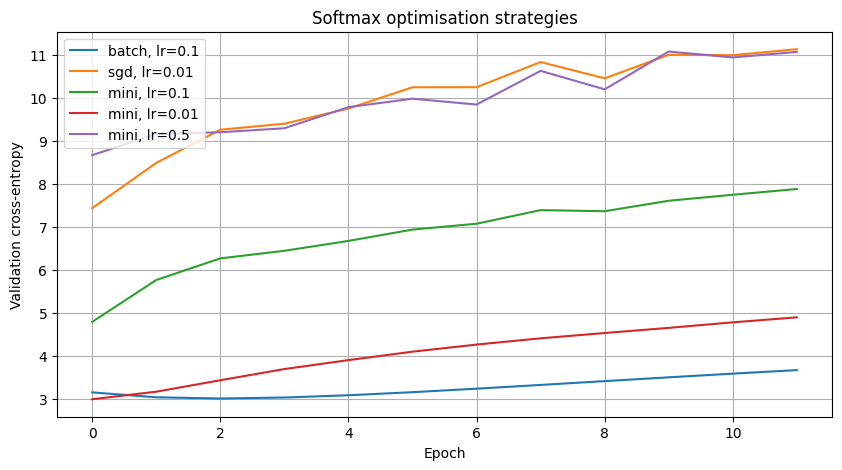

Gradient derivation: for logits Z=XW+b, P=softmax(Z), one-hot Y,
L=-(1/m) sum_i sum_c Y_ic log(P_ic), hence dL/dW = X^T(P-Y)/m and dL/db = column_mean(P-Y).
Batch updates once/epoch; SGD updates per example (noisier); mini-batch balances noise and efficiency.


In [ ]:
# Use PCA-reduced features and a smaller training subset for a quick, reproducible experiment.
n_opt=min(2500,N)
if n_opt==N: opt_idx=np.arange(N)
else: opt_idx,_=train_test_split(np.arange(N),train_size=n_opt,random_state=RANDOM_STATE,stratify=y)
Xo,yo=X[opt_idx],y[opt_idx]
Xo_tr,Xo_va,yo_tr,yo_va=train_test_split(Xo,yo,test_size=.2,random_state=RANDOM_STATE,stratify=yo)
scaler=StandardScaler()
Xo_tr_s=scaler.fit_transform(Xo_tr)
Xo_va_s=scaler.transform(Xo_va)
kopt=min(40,Xo_tr_s.shape[0]-1)
pca_opt=PCA(n_components=kopt,svd_solver="randomized",random_state=RANDOM_STATE)
Xo_tr_s=pca_opt.fit_transform(Xo_tr_s)
Xo_va_s=pca_opt.transform(Xo_va_s)
# Scale features for numerical stability.
Xo_tr_s = Xo_tr_s / (np.std(Xo_tr_s)+1e-8)
Xo_va_s = Xo_va_s / (np.std(Xo_tr_s)+1e-8)
Yoh=np.eye(C)[yo_tr]
Yval=np.eye(C)[yo_va]

def softmax(z):
    z=z-np.max(z,axis=1,keepdims=True)
    e=np.exp(z)
    return e/e.sum(axis=1,keepdims=True)
def ce_loss(Xm, Ym, W, b):
    P=softmax(Xm@W+b)
    return -np.mean(np.sum(Ym*np.log(P+1e-12),axis=1))
def train_softmax(strategy="mini", lr=.1, epochs=15, batch_size=64):
    rng=np.random.default_rng(RANDOM_STATE)
    W=np.zeros((Xo_tr_s.shape[1],C)); b=np.zeros(C)
    hist=[]
    n=len(Xo_tr_s)
    for ep in range(epochs):
        if strategy=="batch":
            batches=[np.arange(n)]
        elif strategy=="sgd":
            perm=rng.permutation(n); batches=[perm[i:i+1] for i in range(n)]
        else:
            perm=rng.permutation(n); batches=[perm[i:i+batch_size] for i in range(0,n,batch_size)]
        for ids in batches:
            xb=Xo_tr_s[ids]; yb=Yoh[ids]
            p=softmax(xb@W+b)
            gradW=xb.T@(p-yb)/len(ids)
            gradb=np.mean(p-yb,axis=0)
            W-=lr*gradW
            b-=lr*gradb
        hist.append((ce_loss(Xo_tr_s,Yoh,W,b),ce_loss(Xo_va_s,Yval,W,b)))
    return W,b,np.array(hist)

histories={}
for strategy,lr in [("batch",.1),("sgd",.01),("mini",.1),("mini",.01),("mini",.5)]:
    _,_,h=train_softmax(strategy=strategy,lr=lr,epochs=12,batch_size=64)
    histories[f"{strategy}, lr={lr}"]=h
plt.figure(figsize=(10,5))
for label,h in histories.items(): plt.plot(h[:,1],label=label)
plt.xlabel("Epoch"); plt.ylabel("Validation cross-entropy"); plt.title("Softmax optimisation strategies")
plt.legend(); plt.grid(True); plt.show()
print("Gradient derivation: for logits Z=XW+b, P=softmax(Z), one-hot Y,")
print("L=-(1/m) sum_i sum_c Y_ic log(P_ic), hence dL/dW = X^T(P-Y)/m and dL/db = column_mean(P-Y).")
print("Batch updates once/epoch; SGD updates per example (noisier); mini-batch balances noise and efficiency.")

## Task 9 — Organise performance, confusion matrix, timing and model size

,n_images,features,model,accuracy,macro_precision,macro_recall,macro_f1,train_seconds,inference_ms_per_image,feature_count
4,1000,PCA100,KNN_k5,0.390909,0.459729,0.390985,0.385442,0.002532,0.094582,100
3,1000,PCA100,LogisticRegression,0.346753,0.338801,0.346804,0.339367,5.951501,0.002234,100
5,1000,PCA100,RandomForest,0.430519,0.424197,0.430625,0.414285,3.888314,0.022084,100
1,1000,raw,KNN_k5,0.311039,0.424874,0.311056,0.296284,0.010668,1.395859,4096
0,1000,raw,LogisticRegression,0.331818,0.332983,0.331960,0.329679,68.684302,0.028451,4096
2,1000,raw,RandomForest,0.477273,0.479454,0.477373,0.464528,15.805052,0.044619,4096
10,5000,PCA100,KNN_k5,0.331081,0.387743,0.329867,0.312889,0.000997,0.034520,100
9,5000,PCA100,LogisticRegression,0.271622,0.267882,0.271777,0.267787,4.159786,0.001213,100
11,5000,PCA100,RandomForest,0.329730,0.305002,0.329549,0.303377,1.814307,0.032120,100
7,5000,raw,KNN_k5,0.279730,0.382999,0.278515,0.247815,0.012788,0.728037,4096


Best measured setting: {'n_images': 1000, 'features': 'raw', 'model': 'RandomForest', 'accuracy': 0.4772727272727273, 'macro_precision': 0.47945429957238445, 'macro_recall': 0.4773729487457529, 'macro_f1': 0.46452825440560985, 'train_seconds': 15.805051807999916, 'inference_ms_per_image': 0.04461913376620965, 'feature_count': 4096}


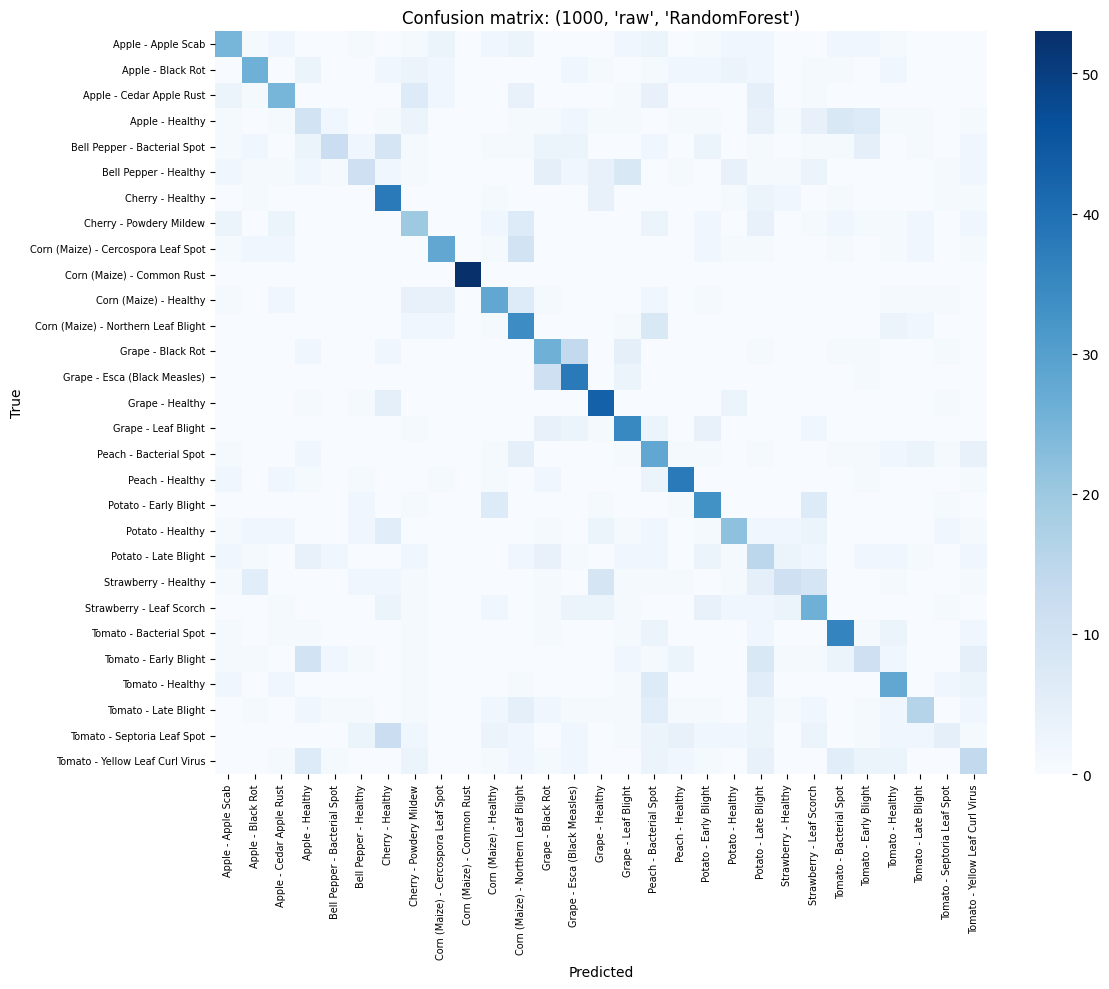

Model-size estimates: sklearn models do not expose a single universal parameter count.
For a linear model, parameters ≈ features × classes + classes; float32 storage ≈ parameters × 4 bytes.
For a PCA model, add the PCA component matrix (components × raw_features) if stored on-device.


In [ ]:
# Results from Task 5 include accuracy, macro precision/recall/F1, fit time and inference time.
display(results_df.sort_values(["n_images","features","model"]))
best_row=results_df.sort_values("accuracy",ascending=False).iloc[0]
print("Best measured setting:", best_row.to_dict())

# Confusion matrix for the best saved model setting.
key=(int(best_row["n_images"]),best_row["features"],best_row["model"])
yt,yp=all_predictions[key]
cm=confusion_matrix(yt,yp,labels=np.arange(C))
plt.figure(figsize=(12,10)); sns.heatmap(cm,cmap="Blues",xticklabels=class_names_valid,
    yticklabels=class_names_valid); plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"Confusion matrix: {key}"); plt.xticks(rotation=90,fontsize=7); plt.yticks(fontsize=7); plt.tight_layout(); plt.show()

# Parameter count/memory estimates are approximations and depend on implementation.
print("Model-size estimates: sklearn models do not expose a single universal parameter count.")
print("For a linear model, parameters ≈ features × classes + classes; float32 storage ≈ parameters × 4 bytes.")
print("For a PCA model, add the PCA component matrix (components × raw_features) if stored on-device.")

## Task 10 — Compare theory with observed behaviour

In [ ]:
# Compact evidence table to help compare PCA information retention with classifier performance.
summary = results_df.pivot_table(index=["n_images","model"],columns="features",
                                 values=["accuracy","macro_f1","train_seconds","inference_ms_per_image"])
display(summary)
print("Interpretation prompts:")
print("1) PCA explained variance is not the same as classification accuracy: discarded low-variance directions may carry class information.")
print("2) Check whether PCA improves runtime or generalisation, and whether the accuracy loss is acceptable.")
print("3) Compare Task 6's train-validation gap with Task 7's bootstrap variance proxy.")
print("4) Numerical conditioning can explain optimisation sensitivity, but implementation and regularisation also matter.")

accuracy           inference_ms_per_image  \
features                       PCA100       raw                 PCA100   
n_images model                                                           
1000     KNN_k5              0.390909  0.311039               0.094582   
         LogisticRegression  0.346753  0.331818               0.002234   
         RandomForest        0.430519  0.477273               0.022084   
5000     KNN_k5              0.331081  0.279730               0.034520   
         LogisticRegression  0.271622  0.272973               0.001213   
         RandomForest        0.329730  0.408108               0.032120   
8700     KNN_k5              0.409770  0.344253               0.073909   
         LogisticRegression  0.350575  0.324138               0.001512   
         RandomForest        0.398851  0.477011               0.013522   

                                       macro_f1           train_seconds  \
features                          raw    PCA100       raw        PCA100   
n_images model                                                            
1000     KNN_k5              1.395859  0.385442  0.296284      0.002532   
         LogisticRegression  0.028451  0.339367  0.329679      5.951501   
         RandomForest        0.044619  0.414285  0.464528      3.888314   
5000     KNN_k5              0.728037  0.312889  0.247815      0.000997   
         LogisticRegression  0.037012  0.267787  0.267884      4.159786   
         RandomForest        0.059731  0.303377  0.397180      1.814307   
8700     KNN_k5              1.547937  0.403450  0.329468      0.001410   
         LogisticRegression  0.033945  0.340045  0.322250      4.572654   
         RandomForest        0.032350  0.379306  0.467344      4.989032   

                                        
features                           raw  
n_images model                          
1000     KNN_k5               0.010668  
         LogisticRegression  68.684302  
         RandomForest        15.805052  
5000     KNN_k5               0.012788  
         LogisticRegression  44.704816  
         RandomForest         6.735064  
8700     KNN_k5               0.010483  
         LogisticRegression  70.940757  
         RandomForest        16.857684

Interpretation prompts:
1) PCA explained variance is not the same as classification accuracy: discarded low-variance directions may carry class information.
2) Check whether PCA improves runtime or generalisation, and whether the accuracy loss is acceptable.
3) Compare Task 6's train-validation gap with Task 7's bootstrap variance proxy.
4) Numerical conditioning can explain optimisation sensitivity, but implementation and regularisation also matter.


## Task 11 — Is deep learning justified?

In [ ]:
# Evidence-based comparison from this experiment.
best_raw = results_df[results_df.features=="raw"].sort_values("accuracy",ascending=False).head(1)
best_pca = results_df[results_df.features.str.startswith("PCA")].sort_values("accuracy",ascending=False).head(1)
print("Best raw-feature baseline:\n", best_raw.to_string(index=False))
print("Best PCA-feature baseline:\n", best_pca.to_string(index=False))
print(f"Image representation: each image has {H*W:,} pixel features, while there are {C} classes.")
print("Flattened classical models do not explicitly preserve local spatial neighbourhoods.")
print("A CNN can learn hierarchical edges, textures and lesion patterns, but needs validation, compute and careful deployment.")
print("Conclusion should be based on the measured baseline accuracy/F1, confusion matrix, runtime and memory—not on a blanket claim.")

Best raw-feature baseline:
  n_images features        model  accuracy  macro_precision  macro_recall  macro_f1  train_seconds  inference_ms_per_image  feature_count
     1000      raw RandomForest  0.477273         0.479454      0.477373  0.464528      15.805052                0.044619           4096
Best PCA-feature baseline:
  n_images features        model  accuracy  macro_precision  macro_recall  macro_f1  train_seconds  inference_ms_per_image  feature_count
     1000   PCA100 RandomForest  0.430519         0.424197      0.430625  0.414285       3.888314                0.022084            100
Image representation: each image has 4,096 pixel features, while there are 29 classes.
Flattened classical models do not explicitly preserve local spatial neighbourhoods.
A CNN can learn hierarchical edges, textures and lesion patterns, but needs validation, compute and careful deployment.
Conclusion should be based on the measured baseline accuracy/F1, confusion matrix, runtime and memory—not

## Task 12 — Design challenge: 38 classes, 20% label noise, ≤50 ms and ≤5 MB

In [ ]:
# 12A. Explicitly document the gap between actual dataset and design challenge.
print(f"Supplied dataset has {C} valid classes, not 38. This notebook cannot measure true 38-class accuracy without examples for 9 additional classes.")
print(f"Uniform-label entropy at {C} classes: {np.log2(C):.4f} bits")
print(f"Uniform-label entropy at 38 classes: {np.log2(38):.4f} bits")
print(f"Random-guess accuracy baseline changes from {1/C:.4%} to {1/38:.4%}")

# 12B. Simulate 20% label corruption on training labels, leaving validation labels clean.
# This is a stress test, not a claim that the supplied dataset itself has 20% noise.
Xn_tr, Xn_va, yn_tr, yn_va = train_test_split(X, y, test_size=.2, random_state=RANDOM_STATE, stratify=y)
rng=np.random.default_rng(RANDOM_STATE)
yn_noisy=yn_tr.copy()
n_flip=int(.20*len(yn_noisy))
flip_idx=rng.choice(len(yn_noisy),n_flip,replace=False)
for i in flip_idx:
    choices=np.delete(np.arange(C),yn_noisy[i])
    yn_noisy[i]=rng.choice(choices)
noise_model=LogisticRegression(max_iter=250,solver="lbfgs",C=1.0)
t0=time.perf_counter(); noise_model.fit(Xn_tr,yn_noisy); fit_noise=time.perf_counter()-t0
t0=time.perf_counter(); pred_noise=noise_model.predict(Xn_va); infer_ms=(time.perf_counter()-t0)/len(Xn_va)*1000
print(f"Clean labels in validation; training labels corrupted at 20%. Accuracy={accuracy_score(yn_va,pred_noise):.4f}, macro-F1={precision_recall_fscore_support(yn_va,pred_noise,average='macro',zero_division=0)[2]:.4f}")
print(f"Fit time={fit_noise:.2f}s, measured CPU inference={infer_ms:.4f} ms/image (Colab CPU; not a smartphone measurement).")

# 12C. Approximate raw linear model parameter memory.
raw_params = X.shape[1]*C + C
raw_float32_mb = raw_params*4/(1024**2)
print(f"Approx. linear classifier weights at {C} classes: {raw_params:,} parameters; float32 weights ≈ {raw_float32_mb:.3f} MiB.")
params_38 = X.shape[1]*38+38
print(f"At 38 classes: {params_38:,} parameters; float32 weights ≈ {params_38*4/(1024**2):.3f} MiB (excluding software/runtime/PCA).")

# 12D. Optional label smoothing loss illustration.
def smoothed_targets(y_idx, n_classes, eps=0.1):
    out=np.full((len(y_idx),n_classes),eps/n_classes)
    out[np.arange(len(y_idx)),y_idx]=1-eps+eps/n_classes
    return out
print("Label smoothing example target for class 0, 5 classes:", smoothed_targets(np.array([0]),5,0.1)[0])
print("Possible adaptation options: (1) PCA dimension/regularisation tuning; (2) label smoothing or noise-robust loss;")
print("(3) compact CNN / quantisation / pruning. Measure accuracy, per-image latency and complete packaged model size on target phone.")
print("Conclusion template: MODIFY the design, then validate with 38-class data and noisy-label experiments. Do not claim smartphone limits are met based on Colab CPU timing.")

Supplied dataset has 29 valid classes, not 38. This notebook cannot measure true 38-class accuracy without examples for 9 additional classes.
Uniform-label entropy at 29 classes: 4.8580 bits
Uniform-label entropy at 38 classes: 5.2479 bits
Random-guess accuracy baseline changes from 3.4483% to 2.6316%
Clean labels in validation; training labels corrupted at 20%. Accuracy=0.2506, macro-F1=0.2490
Fit time=70.59s, measured CPU inference=0.0294 ms/image (Colab CPU; not a smartphone measurement).
Approx. linear classifier weights at 29 classes: 118,813 parameters; float32 weights ≈ 0.453 MiB.
At 38 classes: 155,686 parameters; float32 weights ≈ 0.594 MiB (excluding software/runtime/PCA).
Label smoothing example target for class 0, 5 classes: [0.92 0.02 0.02 0.02 0.02]
Possible adaptation options: (1) PCA dimension/regularisation tuning; (2) label smoothing or noise-robust loss;
(3) compact CNN / quantisation / pruning. Measure accuracy, per-image latency and complete packaged model size on 

## Export the measured results
This cell saves the result tables so you can download them from Colab.

In [ ]:
results_df.to_csv("agrivision_baseline_results.csv", index=False)
cap_df.to_csv("agrivision_capacity_results.csv", index=False)
bv_df.to_csv("agrivision_bias_variance_results.csv", index=False)
print("Saved: agrivision_baseline_results.csv, agrivision_capacity_results.csv, agrivision_bias_variance_results.csv")
try:
    from google.colab import files
    files.download("agrivision_baseline_results.csv")
    files.download("agrivision_capacity_results.csv")
    files.download("agrivision_bias_variance_results.csv")
except Exception:
    pass

Saved: agrivision_baseline_results.csv, agrivision_capacity_results.csv, agrivision_bias_variance_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>